## Imports

- `filter_frames` : analyse toutes les frames d'un dossier et exporte les résultats dans un CSV ;
- `PATH_TO_FRAMES` et `PATH_TO_CSV` : les chemins par défaut du dossier de frames et du CSV de résultats ;
- `read_frame_results_csv` : relit ce CSV pour pouvoir analyser les résultats dans le notebook.


In [2]:
import sys
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import random

sys.path.insert(0, str(Path.cwd().parent.parent))

from pipeline.filter_frame import filter_frames, PATH_TO_FRAMES, PATH_TO_CSV
from pipeline.frame_io import read_frame_results_csv

In [ ]:
filter_frames(PATH_TO_FRAMES, PATH_TO_CSV)

## Aperçu visuel des frames valides et rejetées

1. **Lecture des résultats** : on charge les résultats du filtre.
2. **Séparation** : les frames sont réparties en deux groupes, valides et rejetées.
3. **Échantillonnage** : on tire jusqu'à 10 frames au hasard dans chaque groupe.
4. **Affichage** : chaque groupe est affiché dans une grille de 5 × 2.


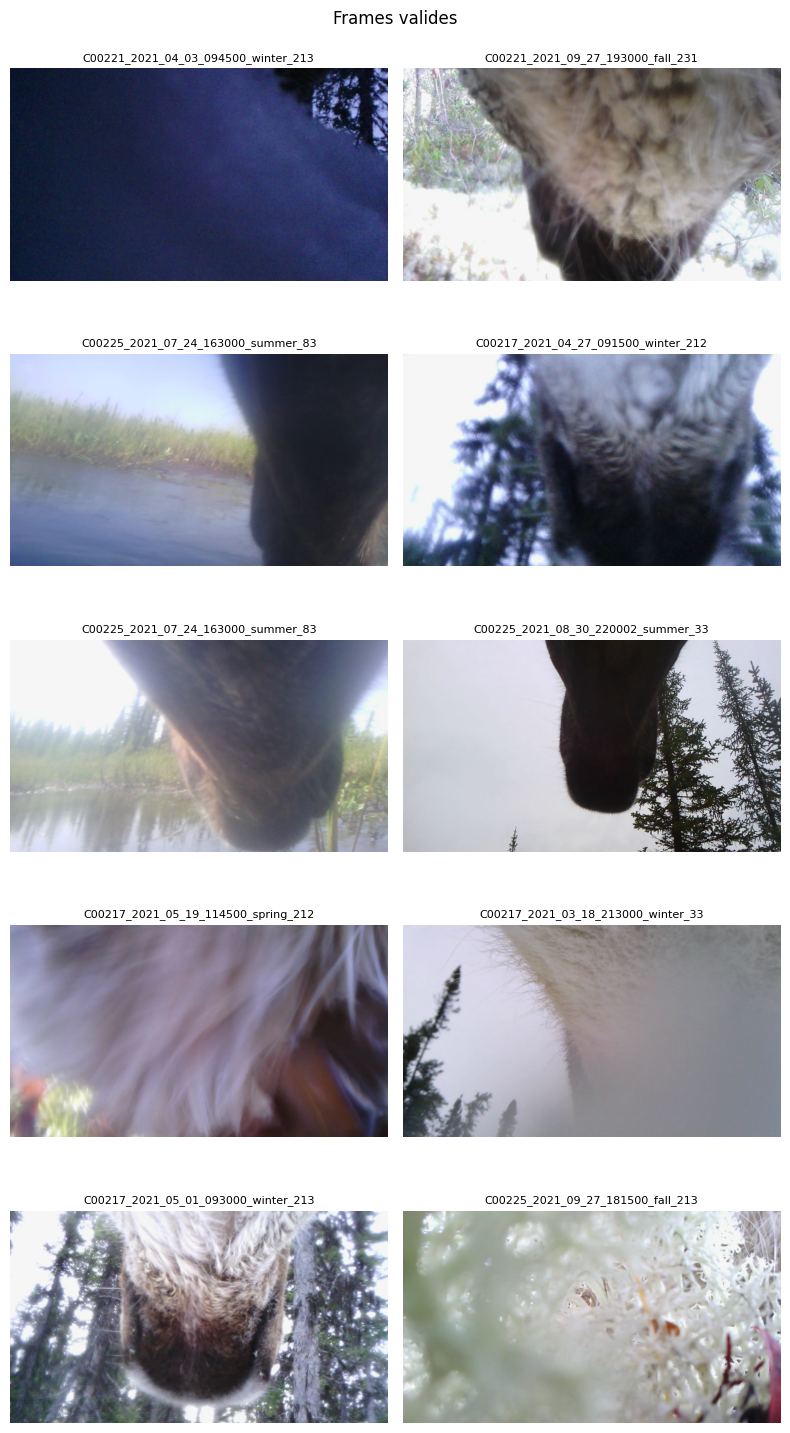

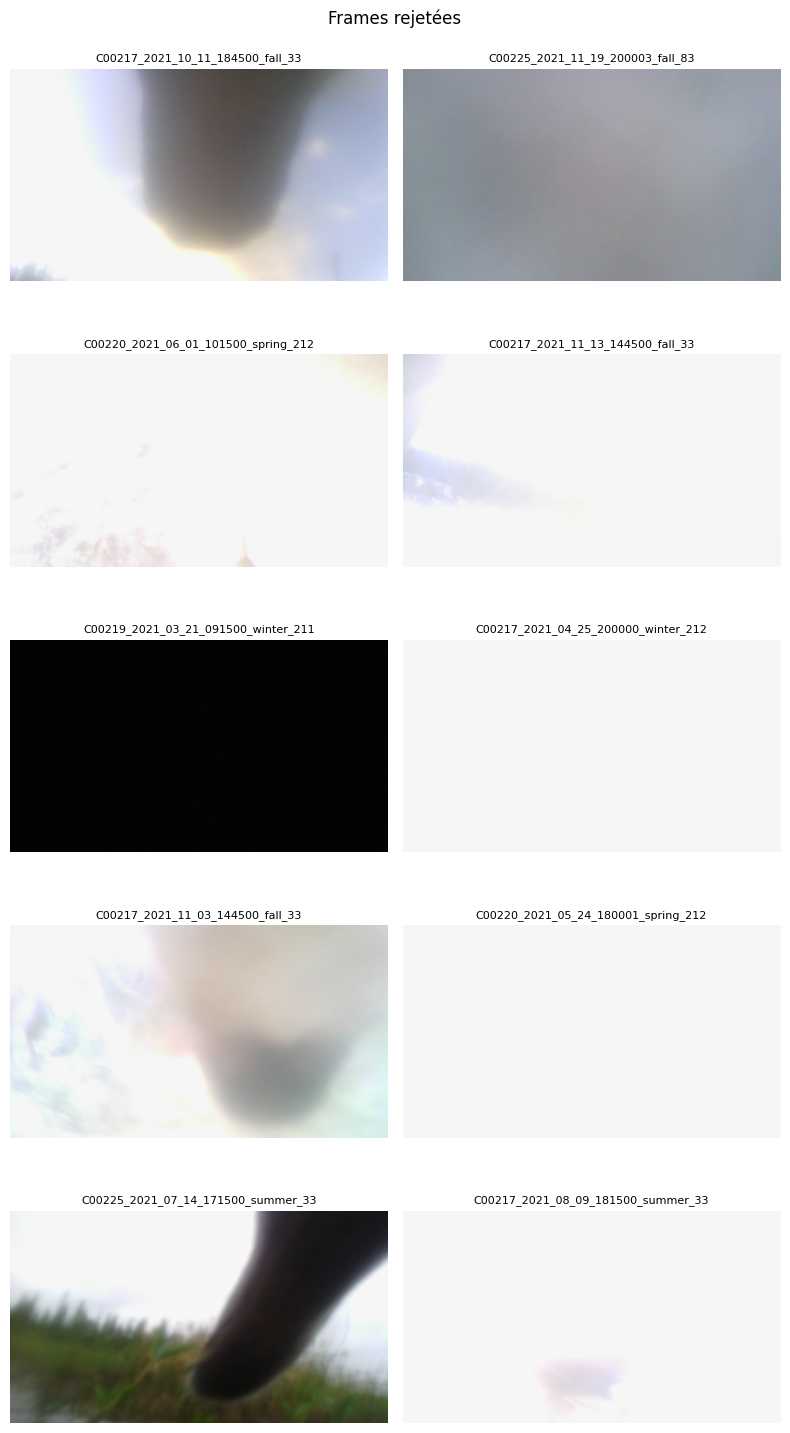

In [10]:
DISPLAY_FRAMES = 10
DISPLAY_WIDTH = 8
DISPLAY_HEIGHT = 15

def afficher_grille(frames, titre):
    fig, axes = plt.subplots(5, 2, figsize=(DISPLAY_WIDTH, DISPLAY_HEIGHT))
    fig.suptitle(titre)

    for ax, frame in zip(axes.flat, frames):
        img = cv2.imread(str(frame.path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.set_title(frame.path.parent.name, fontsize=8)

    for ax in axes.flat:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

frame_results = read_frame_results_csv(PATH_TO_CSV, PATH_TO_FRAMES)

invalid_frames = [f for f in frame_results if not f.result]
valid_frames = [f for f in frame_results if f.result]

random_invalid_frames = random.sample(invalid_frames, min(DISPLAY_FRAMES, len(invalid_frames)))
random_valid_frames = random.sample(valid_frames, min(DISPLAY_FRAMES, len(valid_frames)))

afficher_grille(random_valid_frames, "Frames valides")
afficher_grille(random_invalid_frames, "Frames rejetées")